# Turnover-Rate Interpretability

This notebook inspects the **Turnover** vectorization (topological turnover rate per frame,
for H0, H1 and H2) to check whether it follows the temporal structure of the stimuli.

For each mouse, the turnover rate is **averaged across all trials of the same class**
(mean ± SEM, computed per frame), and segment transitions from the video metadata are marked:

- **Dashed vertical lines**: transitions present at that frame in at least
  `CONSISTENT_FRAC` of the trials of the class (fixed-structure stimuli such as
  RandomDots, GaussianDot, Gabor and PinkNoise).
- **NaturalImages** (classes in `IMAGE_ONSET_LABELS`): only the image (non-background) segments
  are used. A dashed line marks the onset of the k-th image averaged across the videos shown to
  the mouse, and a dotted line marks `IMAGE_OFFSET_FRAMES` (16) frames later, i.e. the average
  first background frame after the image.
- **Grey rug at the bottom**: transitions that vary from video to video (NaturalVideo scene cuts). The rug height is proportional to the fraction of trials with
  a transition at that frame.

Turnover features are read from the precomputed caches (`compute_vectorization_cache.py`),
layout `[H0 | H1 | H2]`, each of length `clip_frames_effective`.
Turnover index `t` counts births/deaths whose endpoint equals `t`, so it is aligned with
segment `frame_start` values (possibly off by one frame, depending on the zigzag time convention).

In [1]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
import numpy as np
import pandas as pd

# Make scripts/utils.py importable
SCRIPTS_DIR = Path("../scripts").resolve()
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils as utils_module
utils_module = importlib.reload(utils_module)

_short_mouse_name = utils_module._short_mouse_name
_discover_mice = utils_module._discover_mice
_build_zz_folder = utils_module._build_zz_folder
build_vectorization_cache_stem = utils_module.build_vectorization_cache_stem
load_vectorization_cache = utils_module.load_vectorization_cache
load_trial_metadata = utils_module.load_trial_metadata
load_video_metadata_json = utils_module.load_video_metadata_json
_coerce_segment_records = utils_module._coerce_segment_records
_to_int_or_none = utils_module._to_int_or_none
_normalize_video_id_token = utils_module._normalize_video_id_token

In [2]:
# -- Configuration ------------------------------------------------------------
DATA_ROOT = Path(
    "/orfeo/scratch/area/ygardinazzi/sensorium_2026/derivatives/"
    "grid-15x15x10_norm-by_minmax"
)
META_ROOT = next(
    p for p in [
        Path("/u/mdmc/anaflom/projects_mdmc/sensorium/metadata"),
        Path("/u/area/anaflom/projects_mdmc/sensorium/metadata"),
    ] if p.exists()
)

# Vectorization cache selection
VECTORIZATION_METHOD = "Turnover"
P_ACTIVE = 70
PER_TRIAL_THRESH = True
CLIP_FRAMES = None          # None = full-trial caches (clip_frames_effective = max valid_frames)

DIM_NAMES = ["H0", "H1", "H2"]

# Frame 0 (all bars are born) and frame valid_frames (all bars die) are boundary
# artefacts that dwarf the rest of the curve. Frames >= valid_frames are always masked.
DROP_FIRST_FRAME = True

# A transition frame shared by at least this fraction of the class trials is drawn as a line;
# the remaining (video-specific) transitions are drawn as a rug.
CONSISTENT_FRAC = 0.5

# H1/H2 show strong onset/offset transients (bars building up / tearing down) that flatten the
# rest of the curve. y-limits are computed ignoring this many frames at each end of the trial
# (the curve is still drawn, just clipped). Set to 0 to use the full range.
Y_LIM_IGNORE_EDGE_FRAMES = 20

# Classes made of images interleaved with a background segment. For these, only the image
# segments are marked: onset of the k-th image averaged across videos (dashed), and the first
# background frame after it, IMAGE_OFFSET_FRAMES later (dotted). The background segment is the
# most frequent segment_ID within each video (s663048 for NaturalImages).
IMAGE_ONSET_LABELS = {"NaturalImages"}
IMAGE_OFFSET_FRAMES = 16

LABELS_ORDER = ["NaturalVideo", "NaturalImages", "PinkNoise", "RandomDots", "GaussianDot", "Gabor"]

# One colour per homology dimension (categorical slots 1-3, fixed order)
DIM_COLOURS = {"H0": "#2a78d6", "H1": "#eb6834", "H2": "#1baf7a"}

SAVE_FIGURES = False
FIGURES_FOLDER = Path("figures").resolve()

MICE = _discover_mice(DATA_ROOT)
print(f"Found {len(MICE)} mice:")
for m in MICE:
    print(f"  {m}")

Found 10 mice:
  dynamic29156-11-10-Video-8744edeac3b4d1ce16b680916b5267ce
  dynamic29228-2-10-Video-8744edeac3b4d1ce16b680916b5267ce
  dynamic29234-6-9-Video-8744edeac3b4d1ce16b680916b5267ce
  dynamic29513-3-5-Video-8744edeac3b4d1ce16b680916b5267ce
  dynamic29514-2-9-Video-8744edeac3b4d1ce16b680916b5267ce
  dynamic29515-10-12-Video-9b4f6a1a067fe51e15306b9628efea20
  dynamic29623-4-9-Video-9b4f6a1a067fe51e15306b9628efea20
  dynamic29647-19-8-Video-9b4f6a1a067fe51e15306b9628efea20
  dynamic29712-5-9-Video-9b4f6a1a067fe51e15306b9628efea20
  dynamic29755-2-8-Video-9b4f6a1a067fe51e15306b9628efea20


## Loading helpers

- `load_turnover_cache`: reads the Turnover cache of one mouse and reshapes it to
  `(n_trials, n_dims, n_frames)`, masking frames outside each trial's valid range with NaN.
- `load_trial_transitions`: for each trial, looks up its `video_ID` in the trial metadata,
  loads the video JSON (`global_meta/videos/<label>-<ID>.json`) and returns the segment
  start frames (excluding frame 0), the start frames of the non-background (image) segments,
  and the video key.

In [3]:
def load_turnover_cache(mouse_id: str) -> dict:
    # Load one mouse's Turnover cache as a (n_trials, n_dims, n_frames) array.
    cache_stem = build_vectorization_cache_stem(
        mouse_name=mouse_id,
        method=VECTORIZATION_METHOD,
        p_active=P_ACTIVE,
        per_trial_thresh=PER_TRIAL_THRESH,
        clip_frames=CLIP_FRAMES,
    )
    cache_path = DATA_ROOT / mouse_id / "cache" / f"{cache_stem}.npz"
    if not cache_path.exists():
        raise FileNotFoundError(f"Missing cache: {cache_path}")

    cache = load_vectorization_cache(cache_path)
    xmat = np.asarray(cache["features"], dtype=np.float64)
    n_frames = int(cache["clip_frames_effective"])
    n_dims = xmat.shape[1] // n_frames
    if n_dims * n_frames != xmat.shape[1]:
        raise RuntimeError(f"Feature length {xmat.shape[1]} is not a multiple of n_frames={n_frames}")

    turnover = xmat.reshape(xmat.shape[0], n_dims, n_frames).copy()
    valid_frames = np.asarray(cache["valid_frames"]).astype(int)

    # Mask frames beyond each trial's valid length (includes the end-of-trial death spike)
    frame_idx = np.arange(n_frames)
    invalid = frame_idx[None, :] >= valid_frames[:, None]
    if DROP_FIRST_FRAME:
        invalid[:, 0] = True
    turnover[np.broadcast_to(invalid[:, None, :], turnover.shape)] = np.nan

    return {
        "turnover": turnover,
        "labels": np.asarray(cache["labels"]).astype(str),
        "trial_ids": np.asarray(cache["trial_ids"]).astype(int),
        "valid_frames": valid_frames,
        "n_frames": n_frames,
        "cache_path": cache_path,
    }


_video_cache = {}


def _parse_video_segments(payload):
    # Return (segment starts excluding 0, start frames of non-background segments).
    seg_records = _coerce_segment_records(payload.get("segments"))
    seg_ids = [str(seg.get("segment_id")) for seg in seg_records]
    background_id = pd.Series(seg_ids).mode().iloc[0] if seg_ids else None

    starts, image_starts = [], []
    for seg, seg_id in zip(seg_records, seg_ids):
        start = _to_int_or_none(seg.get("frame_start"))
        if start is None:
            continue
        if start > 0:
            starts.append(start)
        if seg.get("segment_id") is not None and seg_id != background_id:
            image_starts.append(start)
    return np.array(sorted(starts), dtype=int), np.array(sorted(image_starts), dtype=int)


def load_trial_transitions(mouse_id: str, trial_ids, labels):
    # Return, per trial: segment start frames (excluding 0), image-segment start frames, video key.
    df_meta = load_trial_metadata(META_ROOT, mouse_id)
    trial_to_video = dict(zip(df_meta["trial"].astype(int), df_meta["video_ID"]))

    transitions, image_starts, video_keys = [], [], []
    for trial_id, label in zip(trial_ids, labels):
        video_id = trial_to_video.get(int(trial_id))
        key = (str(label), _normalize_video_id_token(video_id))
        if key not in _video_cache:
            payload, _, _ = load_video_metadata_json(META_ROOT, video_id, label=label)
            if payload is None:
                _video_cache[key] = (False, np.array([], dtype=int), np.array([], dtype=int))
            else:
                _video_cache[key] = (True, *_parse_video_segments(payload))
        found, starts, img_starts = _video_cache[key]
        if not found:
            print(f"[{_short_mouse_name(mouse_id)}] Warning: no video JSON for trial {trial_id} ({label}, {video_id})")
        transitions.append(starts)
        image_starts.append(img_starts)
        video_keys.append(key)
    return transitions, image_starts, video_keys

## Per-class averages

For each mouse and class: mean and SEM of the turnover rate at every frame (NaN-aware, so trials
shorter than the longest one only contribute where they are valid), plus the fraction of trials
that have a segment transition at each frame.

In [4]:
def _ordered_labels(present):
    present = list(dict.fromkeys(present))
    return [l for l in LABELS_ORDER if l in present] + sorted(l for l in present if l not in LABELS_ORDER)


def summarise_mouse(mouse_id: str) -> dict:
    data = load_turnover_cache(mouse_id)
    transitions, image_starts, video_keys = load_trial_transitions(mouse_id, data["trial_ids"], data["labels"])
    n_frames = data["n_frames"]

    per_class = {}
    for label in _ordered_labels(data["labels"]):
        sel = np.flatnonzero(data["labels"] == label)
        x = data["turnover"][sel]                                  # (n_trials, n_dims, n_frames)
        n_valid = np.sum(np.isfinite(x[:, 0, :]), axis=0)          # trials contributing per frame
        mean = np.nanmean(x, axis=0)
        sem = np.nanstd(x, axis=0, ddof=1) / np.sqrt(np.maximum(n_valid, 1))

        trans_count = np.zeros(n_frames)
        for i in sel:
            t = transitions[i]
            trans_count[t[t < n_frames]] += 1
        trans_frac = trans_count / len(sel)

        # Image classes: average onset of the k-th image across the (unique) videos of the class
        image_onsets = image_offsets = None
        n_videos = len({video_keys[i] for i in sel})
        if label in IMAGE_ONSET_LABELS:
            per_video = {video_keys[i]: image_starts[i] for i in sel if image_starts[i].size}
            n_img = {v.size for v in per_video.values()}
            if len(n_img) != 1:
                raise RuntimeError(f"{label}: videos have different numbers of images: {sorted(n_img)}")
            image_onsets = np.vstack(list(per_video.values())).mean(axis=0)
            image_offsets = image_onsets + IMAGE_OFFSET_FRAMES
            trans_frac = np.zeros(n_frames)  # replaced by the averaged image lines

        per_class[label] = {
            "n_trials": len(sel),
            "max_valid_frames": int(data["valid_frames"][sel].max()),
            "mean": mean,
            "sem": sem,
            "n_valid": n_valid,
            "trans_frac": trans_frac,
            "n_trials_with_transitions": int(sum(len(transitions[i]) > 0 for i in sel)),
            "n_videos": n_videos,
            "image_onsets": image_onsets,
            "image_offsets": image_offsets,
        }
    return {"mouse_id": mouse_id, "n_frames": n_frames, "per_class": per_class}


import warnings

summaries = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)  # all-NaN frames beyond valid range
    for mouse_id in MICE:
        try:
            summaries[mouse_id] = summarise_mouse(mouse_id)
        except FileNotFoundError as exc:
            print(f"[{_short_mouse_name(mouse_id)}] skipped: {exc}")

rows = []
for mouse_id, s in summaries.items():
    for label, c in s["per_class"].items():
        tf = c["trans_frac"]
        rows.append({
            "mouse": _short_mouse_name(mouse_id),
            "label": label,
            "n_trials": c["n_trials"],
            "max_valid_frames": c["max_valid_frames"],
            "trials_with_transitions": c["n_trials_with_transitions"],
            "consistent_transitions": int(np.sum(tf >= CONSISTENT_FRAC)),
            "variable_transition_frames": int(np.sum((tf > 0) & (tf < CONSISTENT_FRAC))),
            "n_videos": c["n_videos"],
            "mean_image_onsets": None if c["image_onsets"] is None else np.round(c["image_onsets"], 1).tolist(),
        })
df_summary = pd.DataFrame(rows)
display(df_summary)

,mouse,label,n_trials,max_valid_frames,trials_with_transitions,consistent_transitions,variable_transition_frames,n_videos,mean_image_onsets
0,rec-29156-11-10,NaturalVideo,523,300,255,0,230,368,None
1,rec-29156-11-10,PinkNoise,59,324,59,11,5,6,None
2,rec-29156-11-10,RandomDots,79,240,79,3,0,8,None
3,rec-29156-11-10,GaussianDot,59,315,59,34,0,6,None
4,rec-29228-2-10,NaturalVideo,527,300,273,0,227,370,None
5,rec-29228-2-10,NaturalImages,59,322,59,0,0,6,"[16.2, 47.3, 79.2, 111.3, 143.7, 175.0, 206.0,..."
6,rec-29228-2-10,PinkNoise,59,324,59,11,3,6,None
7,rec-29228-2-10,Gabor,59,300,59,11,1,6,None
8,rec-29234-6-9,NaturalVideo,530,300,283,0,219,373,None
9,rec-29234-6-9,NaturalImages,60,325,60,0,0,6,"[15.5, 48.3, 80.7, 113.3, 143.8, 173.7, 205.2,..."


## Plots: mean turnover rate per class, one figure per mouse

Rows are classes, columns are homology dimensions. The y-axis is shared within each column
so classes can be compared within a mouse.

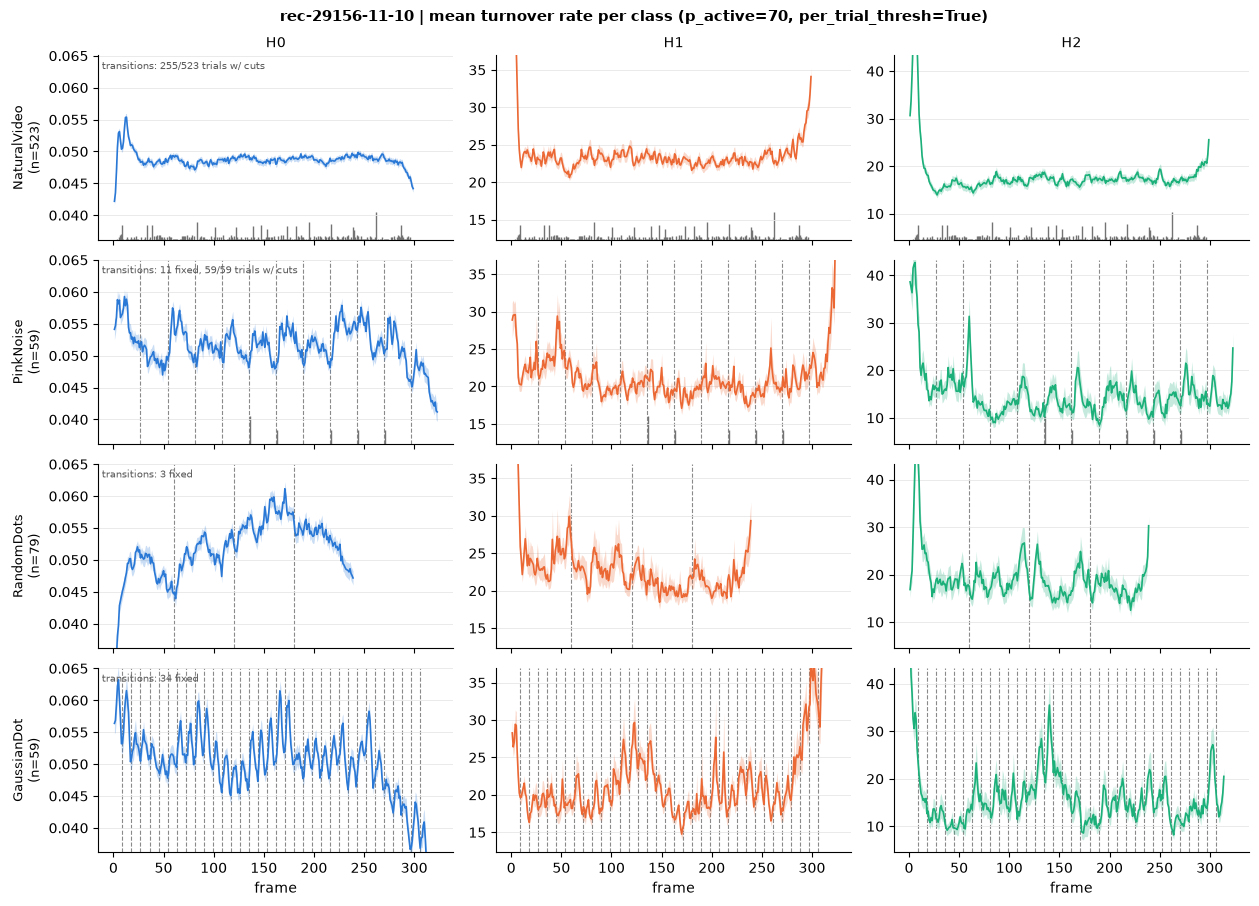

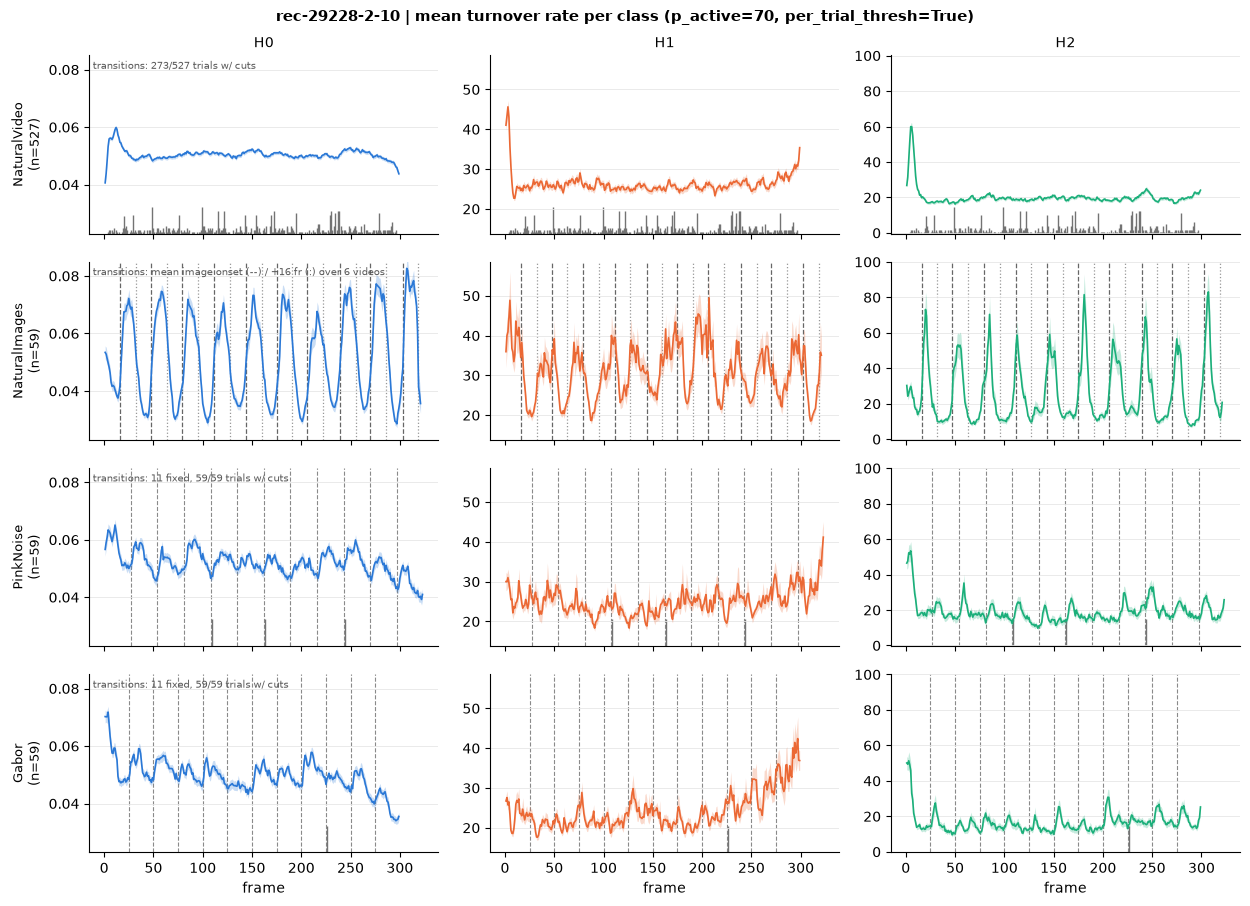

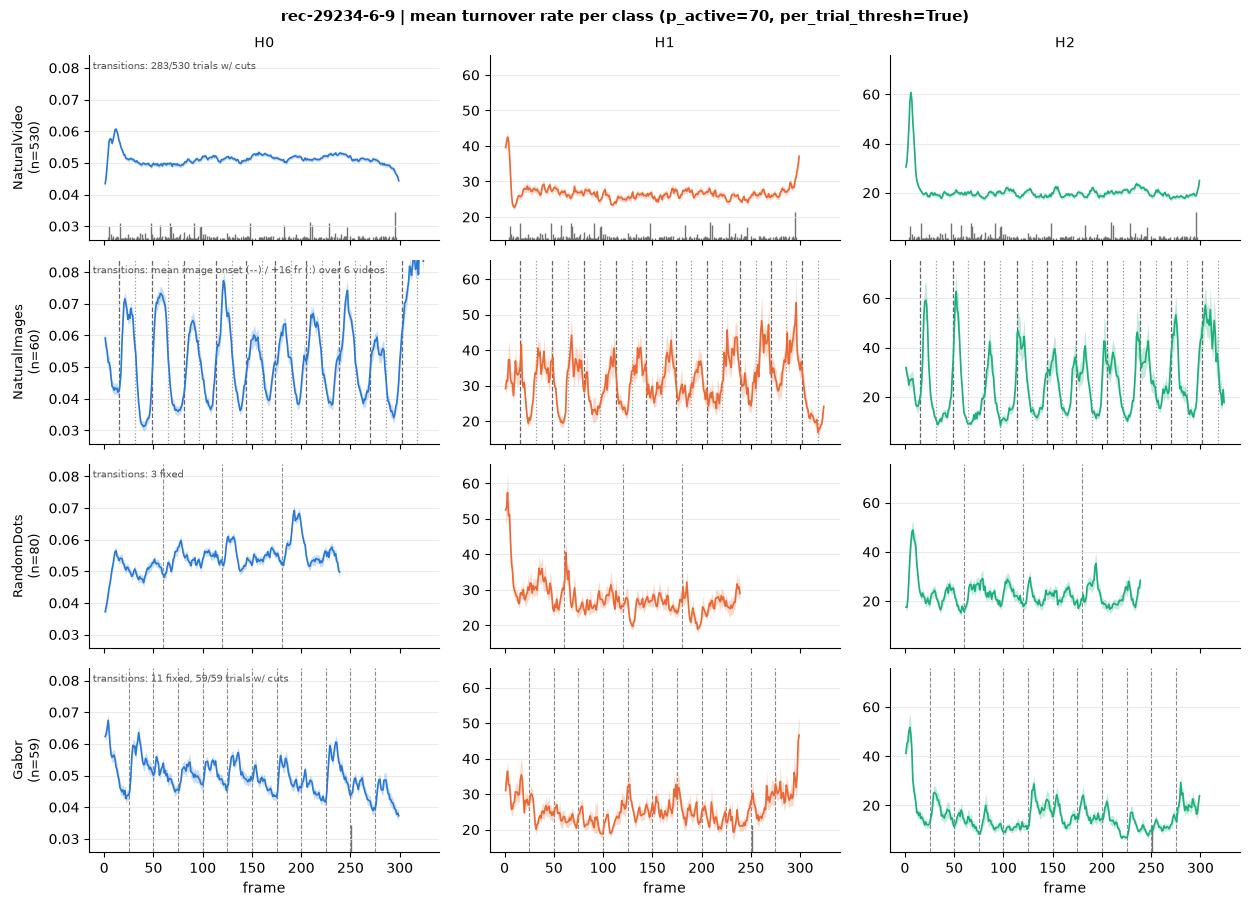

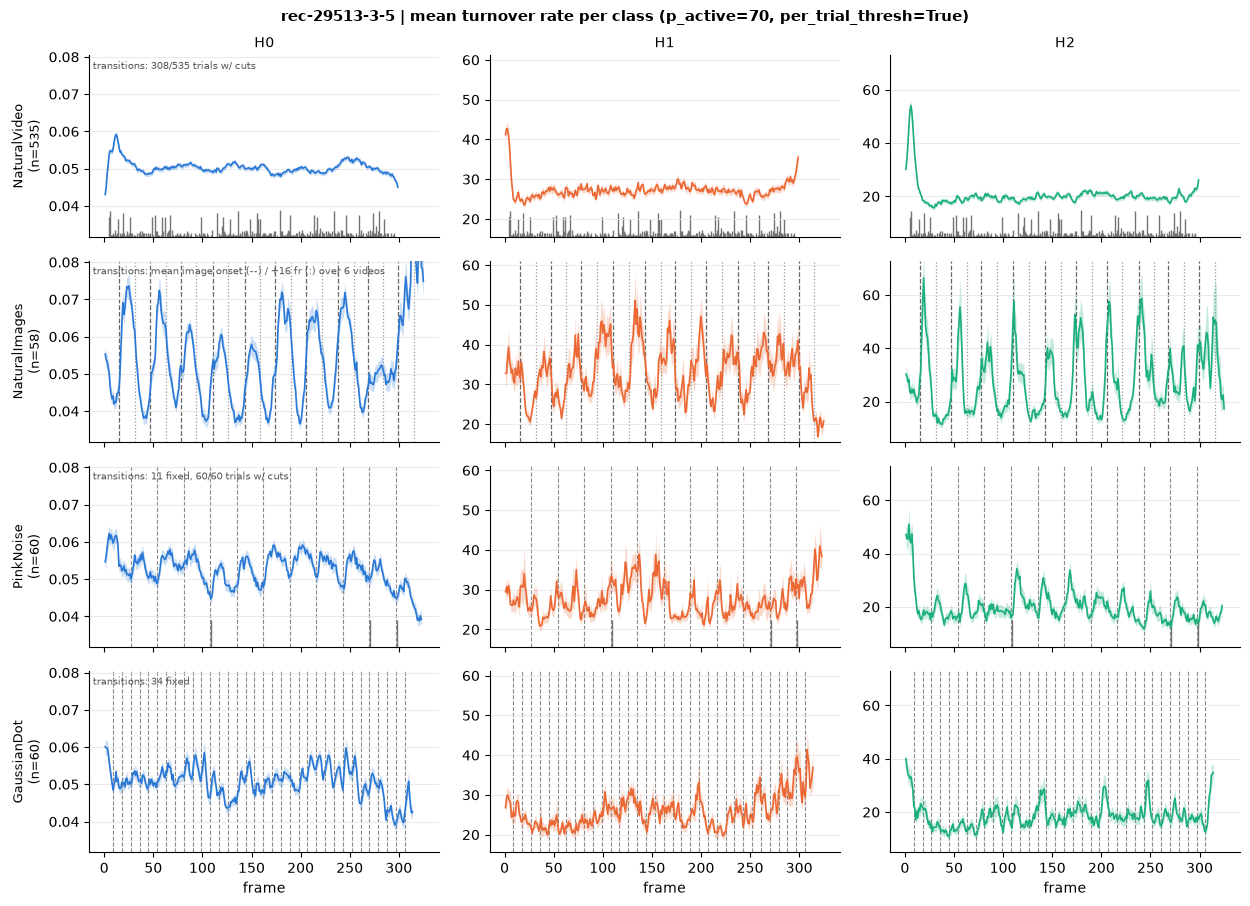

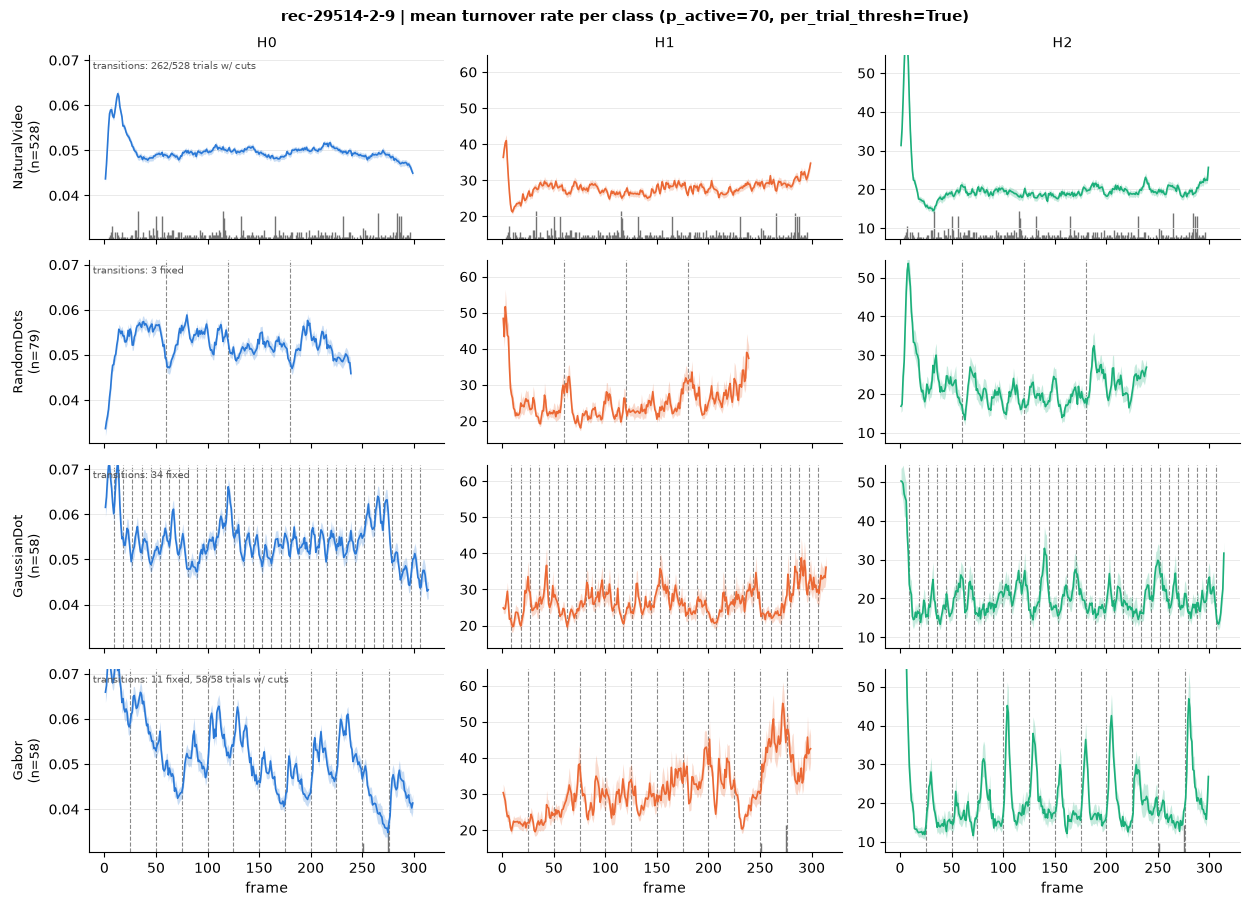

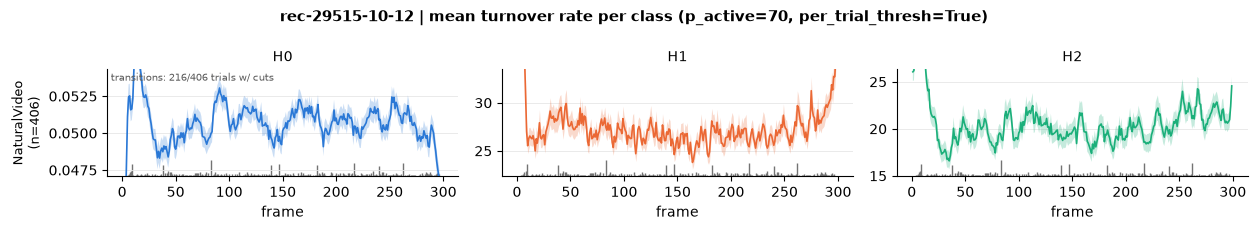

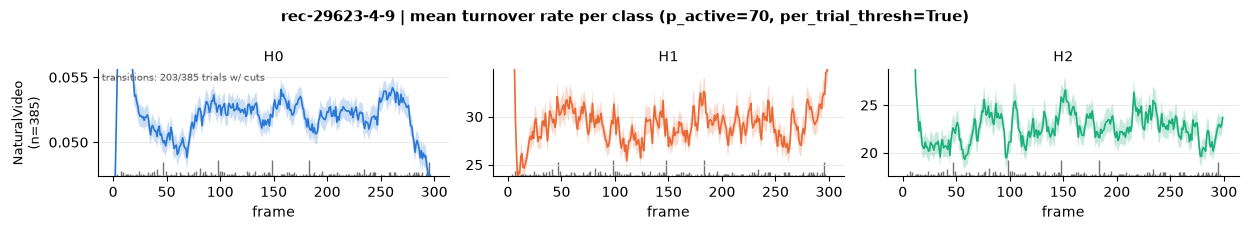

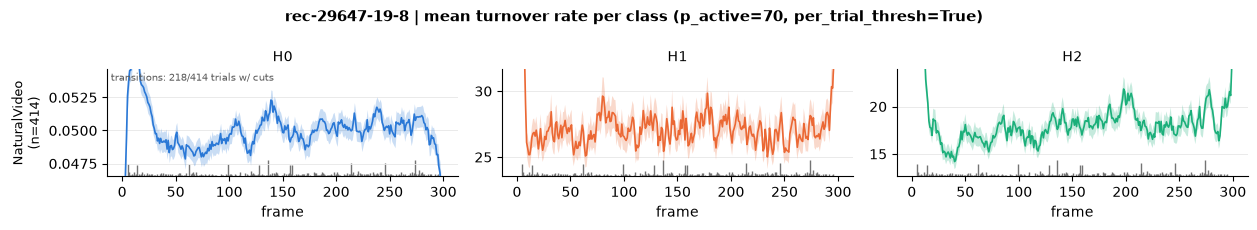

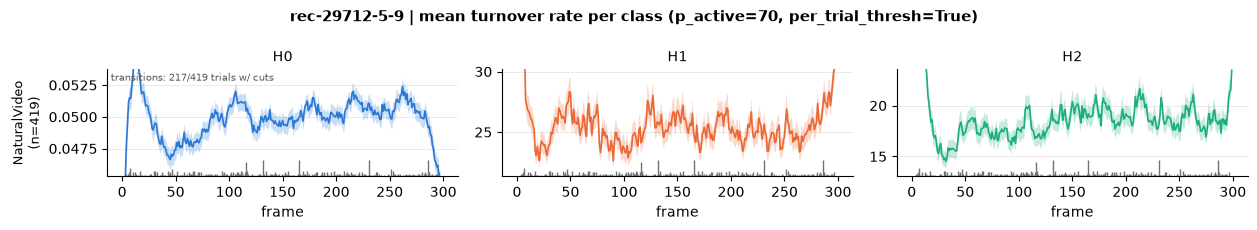

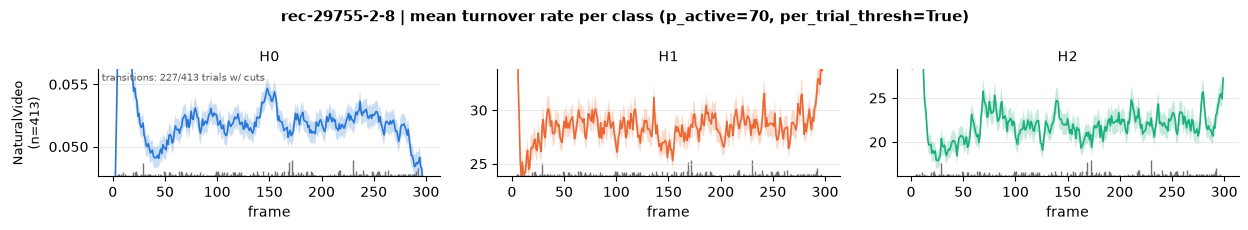

In [5]:
def _mark_image_segments(ax, onsets, offsets):
    # Dashed line at the mean image onset, dotted line at the mean first background frame after it.
    for t in onsets:
        ax.axvline(t, color="0.25", lw=0.9, ls="--", alpha=0.8, zorder=1)
    for t in offsets:
        ax.axvline(t, color="0.55", lw=0.9, ls=":", alpha=0.9, zorder=1)


def _mark_transitions(ax, trans_frac):
    # Dashed lines for consistent transitions, grey rug for video-specific ones.
    consistent = np.flatnonzero(trans_frac >= CONSISTENT_FRAC)
    for t in consistent:
        ax.axvline(t, color="0.35", lw=0.8, ls="--", alpha=0.7, zorder=1)

    variable = np.flatnonzero((trans_frac > 0) & (trans_frac < CONSISTENT_FRAC))
    if variable.size:
        trans = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
        heights = 0.15 * trans_frac[variable] / trans_frac[variable].max()
        ax.vlines(variable, 0, heights, transform=trans, color="0.45", lw=1.0, zorder=1)
    return consistent.size, variable.size


def plot_mouse_turnover(summary: dict):
    per_class = summary["per_class"]
    labels = list(per_class)
    n_dims = len(DIM_NAMES)
    mouse_name = _short_mouse_name(summary["mouse_id"])

    # Shared y-limits per dimension from interior frames only
    ylims = []
    for d in range(n_dims):
        lo, hi = np.inf, -np.inf
        for c in per_class.values():
            e = Y_LIM_IGNORE_EDGE_FRAMES
            interior = slice(e, max(e + 1, c["max_valid_frames"] - e))
            band_lo = (c["mean"][d] - c["sem"][d])[interior]
            band_hi = (c["mean"][d] + c["sem"][d])[interior]
            lo, hi = min(lo, np.nanmin(band_lo)), max(hi, np.nanmax(band_hi))
        pad = 0.08 * (hi - lo)
        ylims.append((lo - pad, hi + pad))

    fig, axes = plt.subplots(
        len(labels), n_dims, figsize=(4.2 * n_dims, 2.3 * len(labels)),
        sharex=True, sharey="col", squeeze=False,
    )
    fig.suptitle(
        f"{mouse_name} | mean turnover rate per class "
        f"(p_active={P_ACTIVE}, per_trial_thresh={PER_TRIAL_THRESH})",
        fontsize=11, fontweight="bold",
    )

    for r, label in enumerate(labels):
        c = per_class[label]
        frames = np.arange(len(c["n_valid"]))
        for d, dim in enumerate(DIM_NAMES):
            ax = axes[r, d]
            n_cons, n_var = _mark_transitions(ax, c["trans_frac"])
            if c["image_onsets"] is not None:
                _mark_image_segments(ax, c["image_onsets"], c["image_offsets"])
            mean, sem = c["mean"][d], c["sem"][d]
            ax.fill_between(frames, mean - sem, mean + sem, color=DIM_COLOURS[dim], alpha=0.25, lw=0, zorder=2)
            ax.plot(frames, mean, color=DIM_COLOURS[dim], lw=1.2, zorder=3)

            ax.set_ylim(*ylims[d])
            ax.grid(axis="y", color="0.9", lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            if r == 0:
                ax.set_title(dim, fontsize=10)
            if d == 0:
                trans_note = []
                if c["image_onsets"] is not None:
                    trans_note.append(
                        f"mean image onset (--) / +{IMAGE_OFFSET_FRAMES} fr (:) over {c['n_videos']} videos"
                    )
                if n_cons:
                    trans_note.append(f"{n_cons} fixed")
                if n_var:
                    trans_note.append(f"{c['n_trials_with_transitions']}/{c['n_trials']} trials w/ cuts")
                ax.set_ylabel(f"{label}\n(n={c['n_trials']})", fontsize=9)
                if trans_note:
                    ax.text(0.01, 0.97, "transitions: " + ", ".join(trans_note), transform=ax.transAxes,
                            fontsize=7, color="0.35", va="top")
            if r == len(labels) - 1:
                ax.set_xlabel("frame")

    fig.tight_layout()
    if SAVE_FIGURES:
        FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
        out = FIGURES_FOLDER / f"turnover_mean_per_class_{mouse_name}_p{P_ACTIVE}_pertrial{int(PER_TRIAL_THRESH)}.png"
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"Saved: {out}")
    plt.show()


for mouse_id, summary in summaries.items():
    plot_mouse_turnover(summary)

## Trial-to-trial correlation of turnover curves: within vs between mice

For every video ID (class + `video_ID`), pairs of presentations are formed:

- **within**: two different presentations of the same video to the same mouse;
- **between**: one presentation in mouse A and one in mouse B (all trial combinations).

For each pair and each homology dimension, the Pearson correlation between the two turnover
curves is computed over the frames valid in both trials, excluding `CORR_IGNORE_EDGE_FRAMES`
frames at each end (onset/offset transients are shared by every trial and would inflate the
correlation regardless of the stimulus).

Note: among the eligible trials, only **NaturalVideo** clips are shown to more than one mouse
(the synthetic and NaturalImages stimuli of the other mice are in the hidden test sets), so the
between-mice comparison is available for NaturalVideo only.

In [6]:
from itertools import combinations

CORR_IGNORE_EDGE_FRAMES = 20   # frames trimmed at each end before correlating
MIN_CORR_FRAMES = 30           # skip pairs with fewer common frames than this

# -- Collect per-trial curves and video keys for all mice --------------------------
trial_records = []   # one entry per trial
trial_curves = []    # (n_dims, n_frames) arrays, NaN-masked outside the valid range
for mouse_id in MICE:
    try:
        data = load_turnover_cache(mouse_id)
    except FileNotFoundError as exc:
        print(f"[{_short_mouse_name(mouse_id)}] skipped: {exc}")
        continue
    _, _, video_keys = load_trial_transitions(mouse_id, data["trial_ids"], data["labels"])
    for i, (label, video_token) in enumerate(video_keys):
        trial_records.append({
            "mouse": _short_mouse_name(mouse_id),
            "trial_id": int(data["trial_ids"][i]),
            "label": label,
            "video_id": video_token,
            "valid_frames": int(data["valid_frames"][i]),
            "row": len(trial_curves),
        })
        trial_curves.append(data["turnover"][i])
df_trials = pd.DataFrame(trial_records)
print(f"Trials: {len(df_trials)} from {df_trials['mouse'].nunique()} mice")


def _pair_correlations(curve_a, curve_b, vf_a, vf_b):
    # Pearson r per dimension over the common, edge-trimmed frames.
    start = max(CORR_IGNORE_EDGE_FRAMES, 1 if DROP_FIRST_FRAME else 0)
    stop = min(vf_a, vf_b) - CORR_IGNORE_EDGE_FRAMES
    if stop - start < MIN_CORR_FRAMES:
        return None, stop - start
    a, b = curve_a[:, start:stop], curve_b[:, start:stop]
    out = []
    for d in range(a.shape[0]):
        if np.std(a[d]) == 0 or np.std(b[d]) == 0:
            out.append(np.nan)
        else:
            out.append(float(np.corrcoef(a[d], b[d])[0, 1]))
    return out, stop - start


# -- Build the pair-level DataFrame ------------------------------------------------
pair_rows = []
for (label, video_id), grp in df_trials.groupby(["label", "video_id"], sort=False):
    if len(grp) < 2:
        continue
    for ia, ib in combinations(grp.index, 2):
        ta, tb = df_trials.loc[ia], df_trials.loc[ib]
        r, n_common = _pair_correlations(
            trial_curves[ta["row"]], trial_curves[tb["row"]], ta["valid_frames"], tb["valid_frames"]
        )
        if r is None:
            continue
        # Order the two mice alphabetically so a mouse pair always appears the same way
        if ta["mouse"] > tb["mouse"]:
            ta, tb = tb, ta
        for dim, r_val in zip(DIM_NAMES, r):
            pair_rows.append({
                "comparison": "within" if ta["mouse"] == tb["mouse"] else "between",
                "label": label,
                "video_id": video_id,
                "mouse_a": ta["mouse"],
                "mouse_b": tb["mouse"],
                "trial_a": int(ta["trial_id"]),
                "trial_b": int(tb["trial_id"]),
                "feature": dim,
                "r": r_val,
                "n_frames": int(n_common),
            })

df_pairs = pd.DataFrame(pair_rows)
df_pairs["label"] = pd.Categorical(df_pairs["label"], categories=_ordered_labels(df_pairs["label"]), ordered=True)
print(f"Pair-level rows: {len(df_pairs)} ({len(df_pairs) // len(DIM_NAMES)} trial pairs x {len(DIM_NAMES)} features)")
display(
    df_pairs[df_pairs["feature"] == DIM_NAMES[0]]
    .groupby(["comparison", "label"], observed=True)
    .agg(n_trial_pairs=("r", "size"), n_videos=("video_id", "nunique"))
)
display(df_pairs.head())

Trials: 5626 from 10 mice


Pair-level rows: 41748 (13916 trial pairs x 3 features)


n_trial_pairs  n_videos
comparison label                                 
between    NaturalVideo            4569      1739
within     NaturalVideo            5151        90
           NaturalImages            784        18
           PinkNoise                792        18
           RandomDots              1062        24
           GaussianDot              783        18
           Gabor                    775        18

,comparison,label,video_id,mouse_a,mouse_b,trial_a,trial_b,feature,r,n_frames
0,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H0,0.388879,260
1,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H1,0.347666,260
2,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H2,0.191671,260
3,between,NaturalVideo,v916600,rec-29156-11-10,rec-29515-10-12,10,10,H0,0.081901,260
4,between,NaturalVideo,v916600,rec-29156-11-10,rec-29515-10-12,10,10,H1,0.142715,260


### Baseline: different videos of the same class

To separate stimulus-specific similarity from structure shared by all trials of a class (slow
drifts, class-wide rhythms), every same-video pair (A, B) gets a **matched control**: trial A is
kept and trial B is replaced by a random trial of **the same mouse as B**, same class, but a
**different video**. This is repeated `N_BASELINE_DRAWS` times per pair, and the draws are averaged.

The control therefore has exactly the same mice, class, number of pairs and trial A as the
original pair, and differs only in whether the video matches. All draws are stored in
`df_baseline_draws`; their per-pair mean is added to `df_pairs` as `r_baseline`.

In [7]:
N_BASELINE_DRAWS = 5
rng = np.random.default_rng(0)

# Candidate pool per (mouse, class): trial-table indices and their video IDs
pool = {
    key: (grp.index.to_numpy(), grp["video_id"].to_numpy())
    for key, grp in df_trials.groupby(["mouse", "label"])
}
trial_index = {(m, t): i for i, (m, t) in enumerate(zip(df_trials["mouse"], df_trials["trial_id"]))}

df_pairs["pair_id"] = df_pairs.groupby(["mouse_a", "trial_a", "mouse_b", "trial_b"], sort=False).ngroup()
pair_table = df_pairs.drop_duplicates("pair_id")[["pair_id", "label", "video_id", "mouse_a", "trial_a", "mouse_b", "trial_b"]]

draw_rows = []
for p in pair_table.itertuples(index=False):
    ta = df_trials.loc[trial_index[(p.mouse_a, p.trial_a)]]
    idx, vids = pool[(p.mouse_b, str(p.label))]
    candidates = idx[vids != p.video_id]
    if candidates.size == 0:
        continue
    for draw, ib in enumerate(rng.choice(candidates, size=min(N_BASELINE_DRAWS, candidates.size), replace=False)):
        tb = df_trials.loc[ib]
        r, n_common = _pair_correlations(
            trial_curves[ta["row"]], trial_curves[tb["row"]], ta["valid_frames"], tb["valid_frames"]
        )
        if r is None:
            continue
        for dim, r_val in zip(DIM_NAMES, r):
            draw_rows.append({
                "pair_id": p.pair_id,
                "draw": draw,
                "trial_b_baseline": int(tb["trial_id"]),
                "video_id_baseline": tb["video_id"],
                "feature": dim,
                "r": r_val,
                "n_frames": int(n_common),
            })

df_baseline_draws = pd.DataFrame(draw_rows)
r_baseline = (
    df_baseline_draws.groupby(["pair_id", "feature"])["r"].mean().rename("r_baseline").reset_index()
)
df_pairs = df_pairs.drop(columns=["r_baseline"], errors="ignore").merge(r_baseline, on=["pair_id", "feature"], how="left")
df_pairs["r_minus_baseline"] = df_pairs["r"] - df_pairs["r_baseline"]
print(f"Baseline draws: {len(df_baseline_draws) // len(DIM_NAMES)} trial pairs")
print(f"Pairs without a baseline: {df_pairs['r_baseline'].isna().sum() // len(DIM_NAMES)}")
display(df_pairs.head())

Baseline draws: 69580 trial pairs
Pairs without a baseline: 0


,comparison,label,video_id,mouse_a,mouse_b,trial_a,trial_b,feature,r,n_frames,pair_id,r_baseline,r_minus_baseline
0,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H0,0.388879,260,0,-0.091562,0.480441
1,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H1,0.347666,260,0,-0.050722,0.398388
2,between,NaturalVideo,v668306,rec-29156-11-10,rec-29515-10-12,0,0,H2,0.191671,260,0,-0.028391,0.220062
3,between,NaturalVideo,v916600,rec-29156-11-10,rec-29515-10-12,10,10,H0,0.081901,260,1,-0.048988,0.130889
4,between,NaturalVideo,v916600,rec-29156-11-10,rec-29515-10-12,10,10,H1,0.142715,260,1,-0.071516,0.214232


### Aggregation per video

Trial pairs of the same video are not independent (each trial enters several pairs, and
NaturalVideo oracle clips are repeated ~10 times). Correlations are therefore first averaged per
**unit** = (comparison, class, video, mouse pair, feature), both for the same-video `r` and for
its matched `r_baseline`. Each box point is one video in one mouse (within) or one video in one
mouse pair (between).

Same-video vs baseline is tested per class and feature with a paired Wilcoxon signed-rank test
on the units (one-sided, same > baseline), Holm-corrected across all tests.

In [8]:
from scipy.stats import wilcoxon


def holm_correction(pvals):
    # Holm-Bonferroni adjusted p-values (step-down, monotone).
    pvals = np.asarray(pvals, dtype=float)
    order = np.argsort(pvals)
    m = len(pvals)
    adjusted = np.maximum.accumulate((m - np.arange(m)) * pvals[order])
    out = np.empty(m)
    out[order] = np.minimum(adjusted, 1.0)
    return out


unit_cols = ["comparison", "label", "video_id", "mouse_a", "mouse_b", "feature"]
df_units = (
    df_pairs.groupby(unit_cols, observed=True)
    .agg(
        r_mean=("r", "mean"),
        r_baseline_mean=("r_baseline", "mean"),
        n_trial_pairs=("r", "size"),
    )
    .reset_index()
)
df_units["r_minus_baseline"] = df_units["r_mean"] - df_units["r_baseline_mean"]

stat_rows = []
for (comparison, label, feature), grp in df_units.groupby(["comparison", "label", "feature"], observed=True):
    g = grp.dropna(subset=["r_mean", "r_baseline_mean"])
    p = wilcoxon(g["r_mean"], g["r_baseline_mean"], alternative="greater").pvalue if len(g) >= 5 else np.nan
    stat_rows.append({
        "comparison": comparison,
        "label": label,
        "feature": feature,
        "n_units": len(g),
        "r_same_video": g["r_mean"].mean(),
        "r_baseline": g["r_baseline_mean"].mean(),
        "difference": g["r_minus_baseline"].mean(),
        "difference_sem": g["r_minus_baseline"].sem(),
        "p_wilcoxon": p,
    })
df_corr_stats = pd.DataFrame(stat_rows)
ok = df_corr_stats["p_wilcoxon"].notna()
df_corr_stats.loc[ok, "p_holm"] = holm_correction(df_corr_stats.loc[ok, "p_wilcoxon"])

for comparison in ["within", "between"]:
    print(f"Average correlation {comparison.upper()} mice: same video vs baseline (different videos, same class)")
    display(
        df_corr_stats[df_corr_stats["comparison"] == comparison]
        .drop(columns="comparison")
        .set_index(["label", "feature"])
        .round({"r_same_video": 3, "r_baseline": 3, "difference": 3, "difference_sem": 3})
    )

Average correlation WITHIN mice: same video vs baseline (different videos, same class)


n_units  r_same_video  r_baseline  difference  \
label         feature                                                  
NaturalVideo  H0           120         0.357       0.000       0.356   
              H1           120         0.126       0.001       0.125   
              H2           120         0.152       0.000       0.152   
NaturalImages H0            18         0.663       0.220       0.443   
              H1            18         0.147       0.030       0.117   
              H2            18         0.406       0.084       0.323   
PinkNoise     H0            18         0.223       0.033       0.190   
              H1            18         0.059       0.015       0.043   
              H2            18         0.071       0.028       0.043   
RandomDots    H0            24         0.241       0.062       0.179   
              H1            24         0.075       0.014       0.061   
              H2            24         0.075       0.009       0.066   
GaussianDot   H0            18         0.224       0.042       0.182   
              H1            18         0.086       0.023       0.063   
              H2            18         0.113       0.008       0.105   
Gabor         H0            18         0.382       0.079       0.302   
              H1            18         0.101       0.037       0.064   
              H2            18         0.136       0.043       0.093   

                       difference_sem    p_wilcoxon        p_holm  
label         feature                                              
NaturalVideo  H0                0.015  9.859759e-22  1.774757e-20  
              H1                0.006  1.146542e-21  1.949121e-20  
              H2                0.009  1.175710e-21  1.949121e-20  
NaturalImages H0                0.026  3.814697e-06  4.577637e-05  
              H1                0.007  3.814697e-06  4.577637e-05  
              H2                0.019  3.814697e-06  4.577637e-05  
PinkNoise     H0                0.022  3.814697e-06  4.577637e-05  
              H1                0.007  1.144409e-05  4.577637e-05  
              H2                0.007  2.670288e-05  5.340576e-05  
RandomDots    H0                0.020  5.960464e-08  8.940697e-07  
              H1                0.009  1.132488e-06  1.472235e-05  
              H2                0.008  5.960464e-08  8.940697e-07  
GaussianDot   H0                0.016  3.814697e-06  4.577637e-05  
              H1                0.008  3.814697e-06  4.577637e-05  
              H2                0.016  3.814697e-06  4.577637e-05  
Gabor         H0                0.022  3.814697e-06  4.577637e-05  
              H1                0.013  7.247925e-05  7.247925e-05  
              H2                0.016  3.814697e-06  4.577637e-05

Average correlation BETWEEN mice: same video vs baseline (different videos, same class)


n_units  r_same_video  r_baseline  difference  \
label        feature                                                  
NaturalVideo H0          1739         0.270       0.002       0.269   
             H1          1739         0.084      -0.001       0.085   
             H2          1739         0.113      -0.000       0.113   

                      difference_sem     p_wilcoxon         p_holm  
label        feature                                                
NaturalVideo H0                0.006  1.755777e-228  3.687132e-227  
             H1                0.004   1.358525e-96   2.581198e-95  
             H2                0.004  5.564950e-112  1.112990e-110

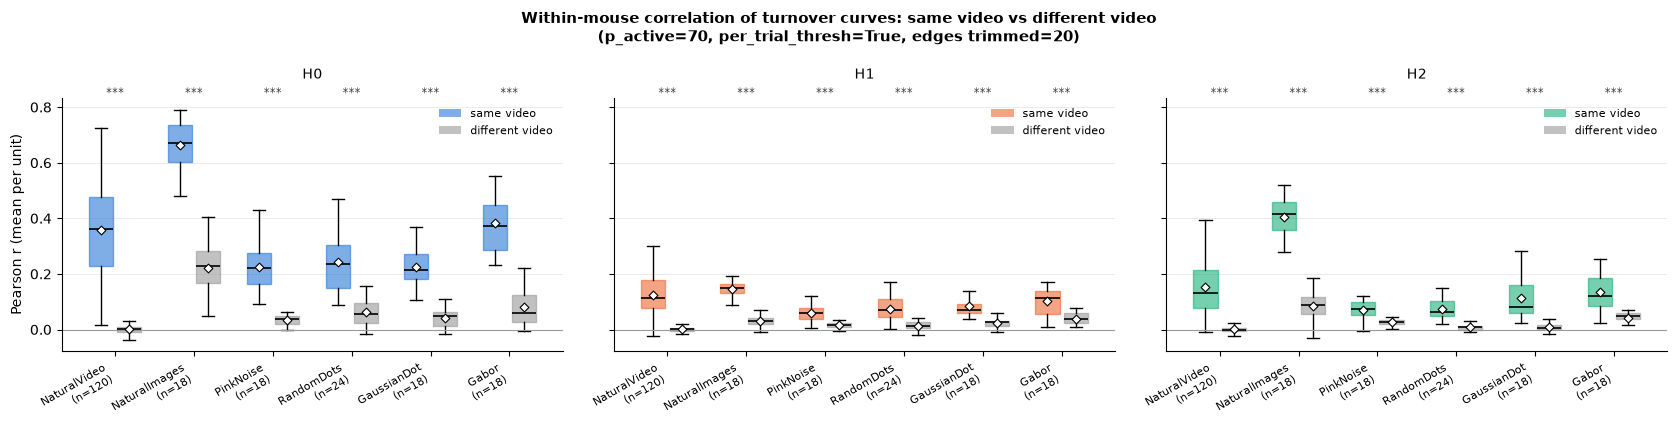

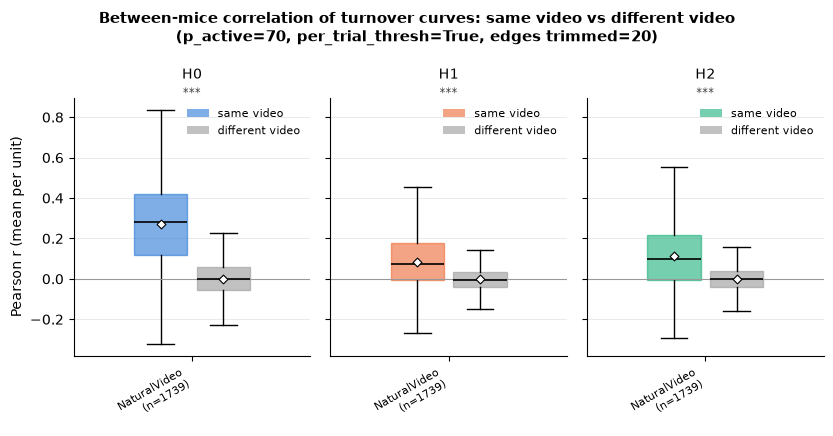

In [9]:
def _stars(p):
    if not np.isfinite(p):
        return ""
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "n.s."


def boxplot_same_vs_baseline(df_u, df_stats, comparison, title):
    # One panel per feature; per class, same-video box (coloured) next to baseline box (grey).
    df_u = df_u[df_u["comparison"] == comparison]
    labels = list(df_u["label"].cat.remove_unused_categories().cat.categories)
    x = np.arange(len(labels))
    w = 0.36

    fig, axes = plt.subplots(
        1, len(DIM_NAMES), figsize=(max(4.5, 1.25 * len(labels) + 1.5) * len(DIM_NAMES) / 1.6, 4.4),
        sharey=True, squeeze=False,
    )
    fig.suptitle(title, fontsize=11, fontweight="bold")
    for d, dim in enumerate(DIM_NAMES):
        ax = axes[0, d]
        sub = df_u[df_u["feature"] == dim]
        for offset, col, colour, name in [
            (-w / 2, "r_mean", DIM_COLOURS[dim], "same video"),
            (w / 2, "r_baseline_mean", "0.6", "different video (baseline)"),
        ]:
            values = [sub.loc[sub["label"] == l, col].dropna().values for l in labels]
            bp = ax.boxplot(
                values, positions=x + offset, widths=w * 0.85, patch_artist=True,
                showfliers=False, medianprops={"color": "black", "lw": 1.2},
            )
            for box in bp["boxes"]:
                box.set_facecolor(colour)
                box.set_alpha(0.6)
                box.set_edgecolor(colour)
            means = [v.mean() if v.size else np.nan for v in values]
            ax.scatter(x + offset, means, marker="D", s=20, color="white", edgecolor="black", lw=0.8, zorder=4)

        # Significance of same > baseline above each class
        stats_dim = df_stats[(df_stats["comparison"] == comparison) & (df_stats["feature"] == dim)].set_index("label")
        for xi, l in zip(x, labels):
            if l in stats_dim.index:
                ax.text(xi, 1.0, _stars(stats_dim.loc[l, "p_holm"]), transform=ax.get_xaxis_transform(),
                        ha="center", va="bottom", fontsize=8, color="0.25")

        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_xticks(x)
        n_units = sub.groupby("label", observed=True).size()
        ax.set_xticklabels([f"{l}\n(n={n_units.get(l, 0)})" for l in labels], fontsize=8, rotation=30, ha="right")
        ax.set_title(dim, fontsize=10, pad=14)
        ax.grid(axis="y", color="0.9", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        if d == 0:
            ax.set_ylabel("Pearson r (mean per unit)")
        handles = [plt.Rectangle((0, 0), 1, 1, fc=DIM_COLOURS[dim], alpha=0.6),
                   plt.Rectangle((0, 0), 1, 1, fc="0.6", alpha=0.6)]
        ax.legend(handles, ["same video", "different video"], frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout()
    return fig


suffix = f"p_active={P_ACTIVE}, per_trial_thresh={PER_TRIAL_THRESH}, edges trimmed={CORR_IGNORE_EDGE_FRAMES}"
for comparison, title in [
    ("within", "Within-mouse correlation of turnover curves: same video vs different video"),
    ("between", "Between-mice correlation of turnover curves: same video vs different video"),
]:
    fig = boxplot_same_vs_baseline(df_units, df_corr_stats, comparison, f"{title}\n({suffix})")
    if SAVE_FIGURES:
        FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            FIGURES_FOLDER / f"turnover_corr_{comparison}_vs_baseline_p{P_ACTIVE}_pertrial{int(PER_TRIAL_THRESH)}.png",
            dpi=150, bbox_inches="tight",
        )
    plt.show()

## Turnover rate vs. frame-to-frame video change

For each trial, the stimulus video (`<RAW_DATA_ROOT>/<mouse>/data/videos/<trial>.npy`,
shape `(36, 64, n_frames)`, pixel range 0-255) is compared frame to frame:

- **MSE**(t) = mean squared error between frame t-1 and frame t (same as
  `ssdatam.videos.compute_videos_time_change`);
- **SSIM**(t) = structural similarity between frame t-1 and frame t, computed with
  `skimage.metrics.structural_similarity` using the Wang et al. (2004) settings
  (Gaussian weights σ = 1.5, `use_sample_covariance=False`, K1 = 0.01, K2 = 0.03, data range 255).

Both curves are assigned to frame t, the frame at which the change appears, so they are aligned
with the turnover index t. SSIM is a similarity (it decreases with change), so correlations use the
dissimilarity **1 − SSIM**. Both MSE and 1 − SSIM grow with visual change: if turnover follows visual
change, both correlations are expected to be positive. (The cache stores raw SSIM.)

For every trial and dimension, the Pearson correlation between the turnover curve (from the
neural response of that trial) and each video measure is computed over the trial's valid frames,
trimmed by `CORR_IGNORE_EDGE_FRAMES` at each end. `NEURAL_LAG_FRAMES` optionally shifts the
turnover curve back in time to account for response latency (0 = no shift).

**Cache.** The MSE/SSIM curves are stored in
`<DERIVATIVES_ROOT>/video_frame_change/video_frame_change_ssim-skimage-sigma<σ>_range<R>.npz`
(one row per mouse x trial, curves NaN-padded to a common length) with a `.json` sidecar
describing the content and parameters. `VIDEO_CHANGE_CACHE_MODE` controls its use:

- `"auto"`: load the cache if it exists, compute only the missing trials, and save if anything was added;
- `"load"`: only load; fail if trials are missing;
- `"recompute"`: recompute everything and overwrite the cache.

In [10]:
from skimage.metrics import structural_similarity

RAW_DATA_ROOT = Path("/orfeo/scratch/area/ygardinazzi/sensorium/data/sensorium_all_2023")
VIDEO_MEASURES = ["MSE", "SSIM"]   # curves stored in the cache
# Measures correlated with turnover: both are dissimilarities (larger = more change between frames)
CORR_MEASURES = {
    "MSE": lambda curves: curves["MSE"],
    "1-SSIM": lambda curves: 1.0 - curves["SSIM"],
}
SSIM_SIGMA = 1.5
SSIM_DATA_RANGE = 255.0
NEURAL_LAG_FRAMES = 0   # turnover at frame t + lag is compared with the video change at frame t

DERIVATIVES_ROOT = Path("/orfeo/scratch/area/ygardinazzi/sensorium_2026/derivatives")
VIDEO_CHANGE_CACHE_MODE = "auto"   # "auto" | "load" | "recompute"


def frame_ssim(x, y, sigma=SSIM_SIGMA, data_range=SSIM_DATA_RANGE):
    # Mean SSIM between paired frames; x, y have shape (H, W, n) and are compared along the last axis.
    return np.array([
        structural_similarity(
            x[:, :, i], y[:, :, i],
            gaussian_weights=True, sigma=sigma, use_sample_covariance=False, data_range=data_range,
        )
        for i in range(x.shape[2])
    ])


def video_change_curves(mouse_id: str, trial_id: int, valid_frames: int) -> dict:
    # MSE and SSIM between consecutive frames, indexed by frame (NaN at frame 0 and beyond valid range).
    video = np.load(RAW_DATA_ROOT / mouse_id / "data" / "videos" / f"{int(trial_id)}.npy").astype(np.float64)
    n_frames = video.shape[2]
    vf = min(int(valid_frames), n_frames)
    prev, curr = video[:, :, : vf - 1], video[:, :, 1:vf]

    curves = {m: np.full(n_frames, np.nan) for m in VIDEO_MEASURES}
    curves["MSE"][1:vf] = np.mean((curr - prev) ** 2, axis=(0, 1))
    curves["SSIM"][1:vf] = frame_ssim(prev, curr)
    return curves


def _corr_with_video(turnover, video_curve, valid_frames):
    # Pearson r per dimension between turnover[t + lag] and video_curve[t] over trimmed valid frames.
    start = max(CORR_IGNORE_EDGE_FRAMES, 1)
    stop = int(valid_frames) - CORR_IGNORE_EDGE_FRAMES - NEURAL_LAG_FRAMES
    if stop - start < MIN_CORR_FRAMES:
        return [np.nan] * turnover.shape[0], stop - start
    v = video_curve[start:stop]
    out = []
    for d in range(turnover.shape[0]):
        t = turnover[d, start + NEURAL_LAG_FRAMES: stop + NEURAL_LAG_FRAMES]
        ok = np.isfinite(t) & np.isfinite(v)
        if ok.sum() < MIN_CORR_FRAMES or np.std(t[ok]) == 0 or np.std(v[ok]) == 0:
            out.append(np.nan)
        else:
            out.append(float(np.corrcoef(t[ok], v[ok])[0, 1]))
    return out, stop - start


# -- Cache of per-trial video change curves -------------------------------------------
import json
from datetime import datetime

import skimage

VIDEO_CHANGE_DIR = DERIVATIVES_ROOT / "video_frame_change"
VIDEO_CHANGE_STEM = f"video_frame_change_ssim-skimage-sigma{SSIM_SIGMA:g}_range{SSIM_DATA_RANGE:g}"
VIDEO_CHANGE_NPZ = VIDEO_CHANGE_DIR / f"{VIDEO_CHANGE_STEM}.npz"
VIDEO_CHANGE_JSON = VIDEO_CHANGE_DIR / f"{VIDEO_CHANGE_STEM}.json"


def load_video_change_cache(path=VIDEO_CHANGE_NPZ):
    # Return {(mouse_full_name, trial_id): {"MSE": curve, "SSIM": curve}} and a per-trial info table.
    data = np.load(path, allow_pickle=False)
    curves, info = {}, []
    for i, (mouse, trial) in enumerate(zip(data["mouse"], data["trial_id"])):
        curves[(str(mouse), int(trial))] = {m: data[m.lower()][i].astype(np.float64) for m in VIDEO_MEASURES}
        info.append({k: data[k][i].item() for k in ["mouse", "trial_id", "label", "video_id", "valid_frames"]})
    return curves, pd.DataFrame(info)


def save_video_change_cache(curves, info_df, path_npz=VIDEO_CHANGE_NPZ, path_json=VIDEO_CHANGE_JSON):
    # Save curves NaN-padded to a common length, plus a JSON sidecar with parameters and conventions.
    info_df = info_df.sort_values(["mouse", "trial_id"]).reset_index(drop=True)
    keys = list(zip(info_df["mouse"], info_df["trial_id"].astype(int)))
    n_max = max(len(curves[k]["MSE"]) for k in keys)
    arrays = {}
    for m in VIDEO_MEASURES:
        arr = np.full((len(keys), n_max), np.nan, dtype=np.float32)
        for i, k in enumerate(keys):
            arr[i, : len(curves[k][m])] = curves[k][m]
        arrays[m.lower()] = arr
    path_npz.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        path_npz,
        mouse=info_df["mouse"].to_numpy(dtype=str),
        trial_id=info_df["trial_id"].astype(np.int64).to_numpy(),
        label=info_df["label"].to_numpy(dtype=str),
        video_id=info_df["video_id"].to_numpy(dtype=str),
        valid_frames=info_df["valid_frames"].astype(np.int64).to_numpy(),
        **arrays,
    )
    meta = {
        "description": "Frame-to-frame change of the stimulus video of each trial (Sensorium 2023).",
        "created": datetime.now().isoformat(timespec="seconds"),
        "created_by": "ZigZagSensorium/notebooks/turnover_intepretability.ipynb",
        "source_videos": str(RAW_DATA_ROOT / "<mouse>" / "data" / "videos" / "<trial>.npy"),
        "n_trials": len(keys),
        "n_mice": int(info_df["mouse"].nunique()),
        "arrays": {
            "mouse": "full recording name (str), one per row",
            "trial_id": "trial number within the recording (int)",
            "label": "video class from metadata (str)",
            "video_id": "global video ID from metadata (str)",
            "valid_frames": "number of valid frames of the trial (int)",
            "mse": f"(n_trials, {n_max}) float32; mse[i, t] = mean((frame_t - frame_(t-1))**2); NaN at t=0 and t >= valid_frames",
            "ssim": f"(n_trials, {n_max}) float32; ssim[i, t] = SSIM(frame_(t-1), frame_t); NaN at t=0 and t >= valid_frames",
        },
        "ssim_parameters": {
            "implementation": f"skimage.metrics.structural_similarity (scikit-image {skimage.__version__})",
            "gaussian_weights": True, "sigma": SSIM_SIGMA, "use_sample_covariance": False,
            "K1": 0.01, "K2": 0.03, "data_range": SSIM_DATA_RANGE,
            "reference": "Wang et al. 2004; mean SSIM over the map (borders cropped by skimage)",
        },
        "trials_included": "valid trials (valid_response & valid_trial) with a Turnover cache entry",
    }
    with open(path_json, "w") as fp:
        json.dump(meta, fp, indent=2)
    print(f"Saved {len(keys)} trials to {path_npz} (+ {path_json.name})")


if VIDEO_CHANGE_CACHE_MODE not in {"auto", "load", "recompute"}:
    raise ValueError(f"Unknown VIDEO_CHANGE_CACHE_MODE: {VIDEO_CHANGE_CACHE_MODE}")

mouse_full_name = {_short_mouse_name(m): m for m in MICE}
cached_curves, cached_info = {}, pd.DataFrame(columns=["mouse", "trial_id", "label", "video_id", "valid_frames"])
if VIDEO_CHANGE_CACHE_MODE != "recompute" and VIDEO_CHANGE_NPZ.exists():
    cached_curves, cached_info = load_video_change_cache()
    print(f"Loaded {len(cached_curves)} trials from {VIDEO_CHANGE_NPZ}")
elif VIDEO_CHANGE_CACHE_MODE == "load":
    raise FileNotFoundError(f"No video-change cache at {VIDEO_CHANGE_NPZ}")

needed = [(mouse_full_name[r.mouse], int(r.trial_id), r) for r in df_trials.itertuples(index=False)]
missing = [x for x in needed if (x[0], x[1]) not in cached_curves]
if missing and VIDEO_CHANGE_CACHE_MODE == "load":
    raise RuntimeError(f"{len(missing)} trials missing from the cache; use VIDEO_CHANGE_CACHE_MODE='auto'")

if missing:
    print(f"Computing video change for {len(missing)} trials ...")
    new_info = []
    for mouse_id, trial_id, rec in missing:
        cached_curves[(mouse_id, trial_id)] = video_change_curves(mouse_id, trial_id, rec.valid_frames)
        new_info.append({"mouse": mouse_id, "trial_id": trial_id, "label": rec.label,
                         "video_id": rec.video_id, "valid_frames": int(rec.valid_frames)})
    cached_info = pd.concat([cached_info, pd.DataFrame(new_info)], ignore_index=True)
    save_video_change_cache(cached_curves, cached_info)

# -- Per-trial correlations ---------------------------------------------------------
video_curves = {}   # (mouse, trial_id) -> {"MSE": curve, "SSIM": curve}, kept for later inspection
video_rows = []
for mouse_id, trial_id, rec in needed:
    curves = cached_curves[(mouse_id, trial_id)]
    video_curves[(rec.mouse, rec.trial_id)] = curves
    for measure, to_dissimilarity in CORR_MEASURES.items():
        r, n_common = _corr_with_video(trial_curves[rec.row], to_dissimilarity(curves), rec.valid_frames)
        for dim, r_val in zip(DIM_NAMES, r):
            video_rows.append({
                "mouse": rec.mouse,
                "trial_id": rec.trial_id,
                "label": rec.label,
                "video_id": rec.video_id,
                "valid_frames": rec.valid_frames,
                "measure": measure,
                "feature": dim,
                "r": r_val,
                "n_frames": int(n_common),
                "lag_frames": NEURAL_LAG_FRAMES,
            })

df_video_corr = pd.DataFrame(video_rows)
df_video_corr["label"] = pd.Categorical(
    df_video_corr["label"], categories=_ordered_labels(df_video_corr["label"]), ordered=True
)
print(f"Rows: {len(df_video_corr)} ({df_trials.shape[0]} trials x {len(CORR_MEASURES)} measures x {len(DIM_NAMES)} features)")
print(f"NaN correlations: {df_video_corr['r'].isna().sum()}")
display(df_video_corr.head())

Loaded 5626 trials from /orfeo/scratch/area/ygardinazzi/sensorium_2026/derivatives/video_frame_change/video_frame_change_ssim-skimage-sigma1.5_range255.npz


Rows: 33756 (5626 trials x 2 measures x 3 features)
NaN correlations: 0


,mouse,trial_id,label,video_id,valid_frames,measure,feature,r,n_frames,lag_frames
0,rec-29156-11-10,0,NaturalVideo,v668306,300,MSE,H0,0.058673,260,0
1,rec-29156-11-10,0,NaturalVideo,v668306,300,MSE,H1,-0.062688,260,0
2,rec-29156-11-10,0,NaturalVideo,v668306,300,MSE,H2,0.113059,260,0
3,rec-29156-11-10,0,NaturalVideo,v668306,300,1-SSIM,H0,0.075049,260,0
4,rec-29156-11-10,0,NaturalVideo,v668306,300,1-SSIM,H1,-0.080278,260,0


### Average per video and mouse

Repeated presentations of the same video to the same mouse are averaged, so each point below is
one video in one mouse.

In [11]:
df_video_corr_units = (
    df_video_corr.groupby(["mouse", "label", "video_id", "measure", "feature"], observed=True)
    .agg(r_mean=("r", "mean"), n_trials=("r", "size"))
    .reset_index()
)

summary_video_corr = (
    df_video_corr_units.groupby(["measure", "label", "feature"], observed=True)["r_mean"]
    .agg(n_units="size", mean="mean", sem="sem", median="median")
    .round(3)
    .unstack("feature")
)
display(summary_video_corr)

n_units               mean                  sem         \
feature                    H0    H1    H2     H0     H1     H2     H0     H1   
measure label                                                                  
1-SSIM  NaturalVideo     3628  3628  3628 -0.088  0.057 -0.031  0.003  0.002   
        NaturalImages      18    18    18 -0.039  0.023 -0.075  0.003  0.005   
        PinkNoise          18    18    18 -0.057  0.014 -0.031  0.008  0.004   
        RandomDots         24    24    24 -0.089  0.033  0.000  0.035  0.020   
        GaussianDot        18    18    18 -0.055 -0.024 -0.023  0.005  0.005   
        Gabor              18    18    18 -0.221  0.033 -0.109  0.029  0.023   
MSE     NaturalVideo     3628  3628  3628 -0.082  0.052 -0.030  0.003  0.002   
        NaturalImages      18    18    18 -0.024  0.015 -0.060  0.003  0.005   
        PinkNoise          18    18    18 -0.054  0.015 -0.029  0.008  0.005   
        RandomDots         24    24    24 -0.094  0.033  0.001  0.034  0.019   
        GaussianDot        18    18    18 -0.053 -0.024 -0.025  0.005  0.004   
        Gabor              18    18    18 -0.209  0.029 -0.104  0.026  0.019   

                             median                
feature                   H2     H0     H1     H2  
measure label                                      
1-SSIM  NaturalVideo   0.002 -0.080  0.043 -0.036  
        NaturalImages  0.003 -0.040  0.021 -0.077  
        PinkNoise      0.003 -0.055  0.015 -0.033  
        RandomDots     0.017 -0.068  0.024 -0.031  
        GaussianDot    0.003 -0.053 -0.023 -0.027  
        Gabor          0.011 -0.215  0.011 -0.100  
MSE     NaturalVideo   0.002 -0.076  0.035 -0.036  
        NaturalImages  0.003 -0.027  0.011 -0.062  
        PinkNoise      0.003 -0.055  0.017 -0.028  
        RandomDots     0.015 -0.091  0.031 -0.009  
        GaussianDot    0.004 -0.054 -0.024 -0.028  
        Gabor          0.010 -0.201  0.024 -0.098

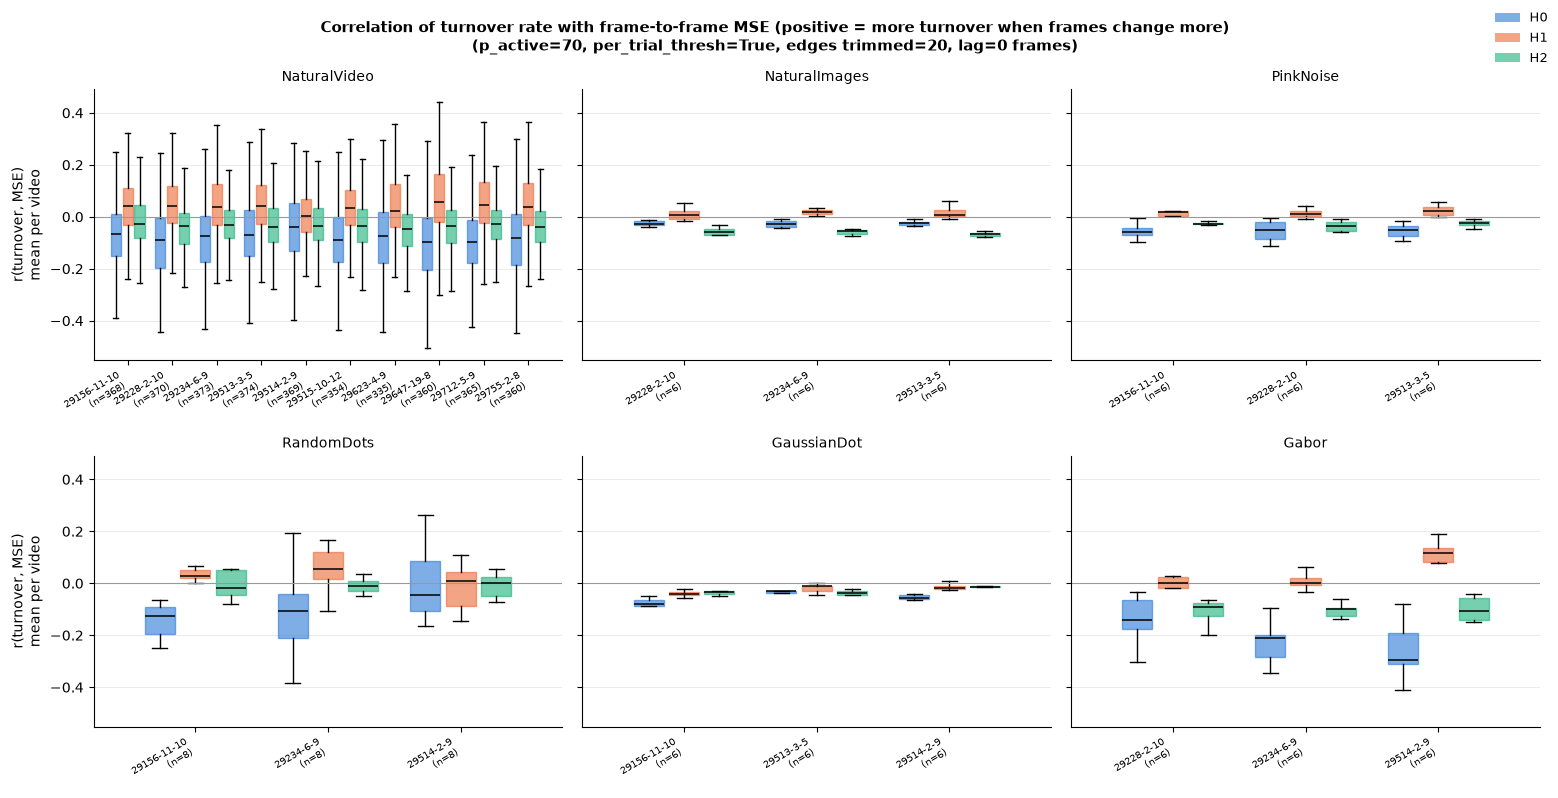

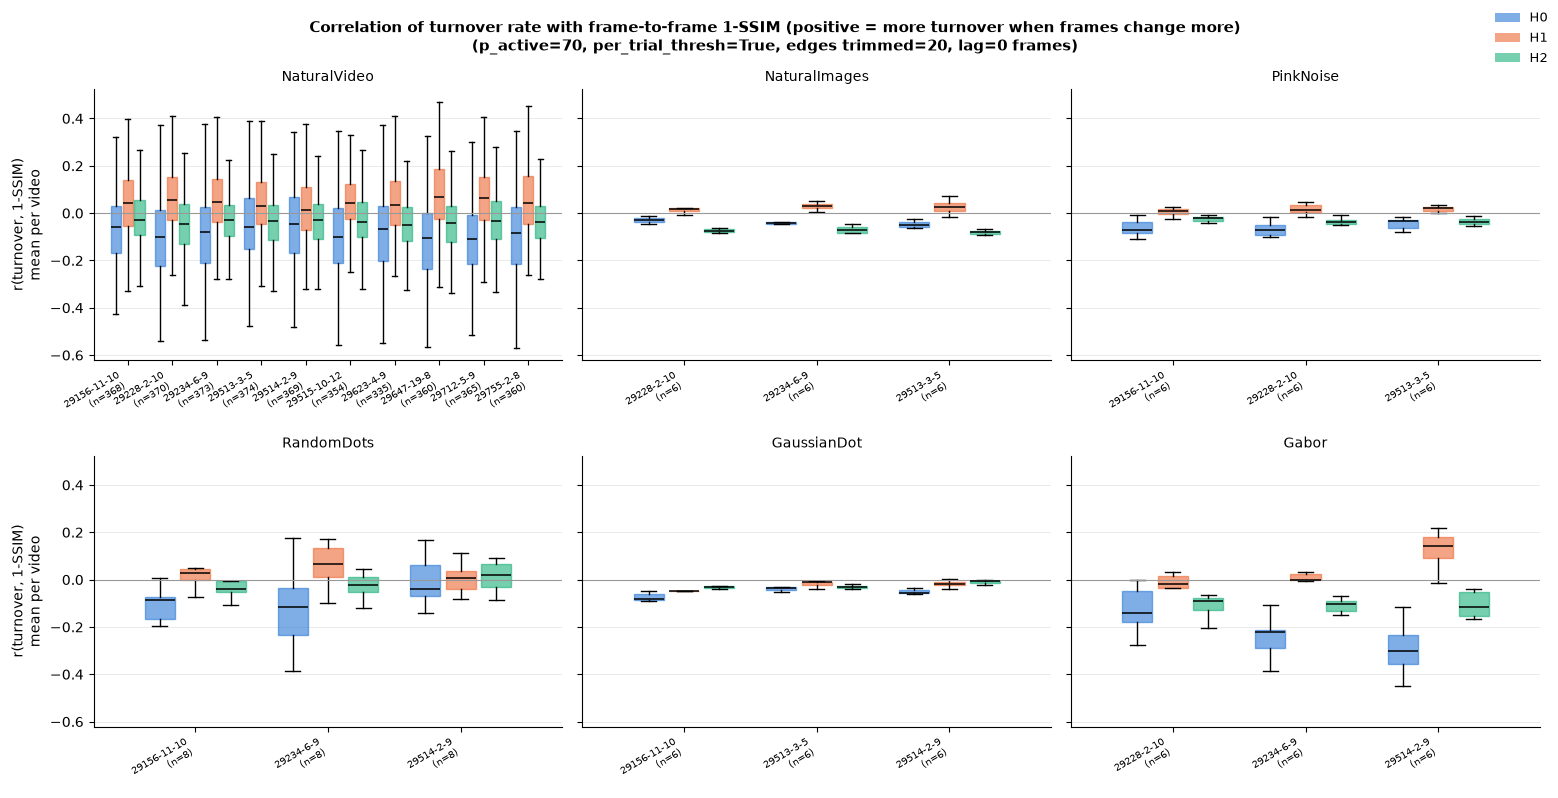

In [12]:
def boxplot_video_corr(df_u, measure, title):
    # One panel per class; per mouse, one box per feature (H0/H1/H2).
    df_m = df_u[df_u["measure"] == measure]
    labels = list(df_m["label"].cat.remove_unused_categories().cat.categories)
    n_cols = 3
    n_rows = int(np.ceil(len(labels) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.2 * n_cols, 4.0 * n_rows), sharey=True, squeeze=False)
    fig.suptitle(title, fontsize=11, fontweight="bold")
    w = 0.8 / len(DIM_NAMES)

    for k, label in enumerate(labels):
        ax = axes.flat[k]
        sub = df_m[df_m["label"] == label]
        mice = sorted(sub["mouse"].unique())
        x = np.arange(len(mice))
        for d, dim in enumerate(DIM_NAMES):
            values = [sub.loc[(sub["mouse"] == m) & (sub["feature"] == dim), "r_mean"].dropna().values for m in mice]
            pos = x + (d - (len(DIM_NAMES) - 1) / 2) * w
            bp = ax.boxplot(values, positions=pos, widths=w * 0.85, patch_artist=True,
                            showfliers=False, medianprops={"color": "black", "lw": 1.1})
            for box in bp["boxes"]:
                box.set_facecolor(DIM_COLOURS[dim])
                box.set_alpha(0.6)
                box.set_edgecolor(DIM_COLOURS[dim])
        n_videos = sub[sub["feature"] == DIM_NAMES[0]].groupby("mouse").size()
        ax.set_xticks(x)
        ax.set_xticklabels([f"{m.replace('rec-', '')}\n(n={n_videos.get(m, 0)})" for m in mice], fontsize=7, rotation=30, ha="right")
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title(label, fontsize=10)
        ax.grid(axis="y", color="0.9", lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        if k % n_cols == 0:
            ax.set_ylabel(f"r(turnover, {measure})\nmean per video")
    for ax in list(axes.flat)[len(labels):]:
        ax.set_visible(False)

    handles = [plt.Rectangle((0, 0), 1, 1, fc=DIM_COLOURS[d], alpha=0.6) for d in DIM_NAMES]
    fig.legend(handles, DIM_NAMES, frameon=False, fontsize=9, loc="upper right")
    fig.tight_layout()
    return fig


suffix = (f"p_active={P_ACTIVE}, per_trial_thresh={PER_TRIAL_THRESH}, "
          f"edges trimmed={CORR_IGNORE_EDGE_FRAMES}, lag={NEURAL_LAG_FRAMES} frames")
for measure in CORR_MEASURES:
    fig = boxplot_video_corr(
        df_video_corr_units, measure,
        f"Correlation of turnover rate with frame-to-frame {measure} "
        f"(positive = more turnover when frames change more)\n({suffix})",
    )
    if SAVE_FIGURES:
        FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_FOLDER / f"turnover_corr_video_{measure.replace('-', 'minus')}_p{P_ACTIVE}_pertrial{int(PER_TRIAL_THRESH)}_lag{NEURAL_LAG_FRAMES}.png",
                    dpi=150, bbox_inches="tight")
    plt.show()

## Event-triggered average of turnover at segment onsets

For every class with discrete segments (all except NaturalVideo), the turnover curves are cut
into windows aligned to the segment onsets and averaged, separately for each mouse.

- **Window length**: the most common segment length of the class (from the video metadata), so all
  windows of a class have the same length. For **NaturalImages** the window is aligned to the
  **image** onset (not the background) and lasts `15 (image) + 12 (background)` frames.
- **No spill-over**: frames of a window that reach the next segment (NaturalImages: the next
  image) are excluded (NaN), so each window only contains the response to one segment.
- **Trial edges**: segments starting before `ETA_EDGE_FRAMES` (i.e. the first segment, which
  contains the trial-onset transient) are excluded, and frames within `ETA_EDGE_FRAMES` of the
  end of the trial are masked (offset transient). Set `ETA_EDGE_FRAMES = 0` to keep everything.
- **Averaging**: windows are first averaged within each trial, then mean ± SEM across trials.
- **Mean removal** (`ETA_REMOVE_MEAN`, default True): each trial's averaged window has its own mean
  over the window subtracted (per feature) before averaging across trials. This removes level
  differences between mice and trials so that only the shape of the response is compared.

Frame index 0 of the window is the first frame of the segment (turnover at the frame where
the segment starts).

In [13]:
ETA_LABELS = ["NaturalImages", "PinkNoise", "RandomDots", "GaussianDot", "Gabor"]
ETA_NATURALIMAGES_WINDOW = 15 + 12      # image + background frames after the image onset
ETA_EDGE_FRAMES = CORR_IGNORE_EDGE_FRAMES
ETA_REMOVE_MEAN = True                  # subtract each trial's mean over the window (per feature)


def _video_events(label, video_token, video_id_raw):
    # Return (event onsets, next-boundary for each onset) for one video.
    # NaturalImages: image onsets, bounded by the next image onset. Others: all segment starts,
    # bounded by the next segment start. The last event is bounded by +inf (valid_frames applies later).
    payload, _, _ = load_video_metadata_json(META_ROOT, video_id_raw, label=label)
    if payload is None:
        return np.array([], dtype=int), np.array([])
    seg_starts, image_starts = _parse_video_segments(payload)
    if label in IMAGE_ONSET_LABELS:
        onsets = image_starts
    else:
        onsets = np.concatenate([[0], seg_starts]).astype(int)   # _parse_video_segments drops frame 0
    onsets = np.unique(onsets)
    bounds = np.append(onsets[1:], np.inf)
    return onsets, bounds


# Window length per class: most common segment length across the class videos
segment_lengths = {}
for label in ETA_LABELS:
    if label in IMAGE_ONSET_LABELS:
        segment_lengths[label] = ETA_NATURALIMAGES_WINDOW
        continue
    lengths = []
    for f in (META_ROOT / "global_meta" / "videos").glob(f"{label}-*.json"):
        with open(f) as fp:
            seg = json.load(fp)["segments"]
        lengths += [e - s for s, e in zip(seg["frame_start"], seg["frame_end"])]
    segment_lengths[label] = int(pd.Series(lengths).mode().iloc[0])
print("Window length (frames) per class:", segment_lengths)

# Raw video_ID per (mouse, trial), needed to read the video JSON
raw_video_id = {}
for mouse_id in MICE:
    meta = load_trial_metadata(META_ROOT, mouse_id)
    for t, v in zip(meta["trial"].astype(int), meta["video_ID"]):
        raw_video_id[(_short_mouse_name(mouse_id), int(t))] = v

events_cache = {}
eta_trials = []   # one row per trial: per-trial mean window (n_dims, W) + event counts
for rec in df_trials[df_trials["label"].isin(ETA_LABELS)].itertuples(index=False):
    W = segment_lengths[rec.label]
    key = (rec.label, rec.video_id)
    if key not in events_cache:
        events_cache[key] = _video_events(rec.label, rec.video_id, raw_video_id[(rec.mouse, rec.trial_id)])
    onsets, bounds = events_cache[key]

    curve = trial_curves[rec.row]                       # (n_dims, n_frames), NaN outside valid range
    last_ok = rec.valid_frames - ETA_EDGE_FRAMES        # frames >= last_ok are masked
    windows = []
    for onset, bound in zip(onsets, bounds):
        if onset < ETA_EDGE_FRAMES or onset >= last_ok:
            continue
        frames = onset + np.arange(W)
        keep = (frames < bound) & (frames < last_ok) & (frames < curve.shape[1])
        win = np.full((curve.shape[0], W), np.nan)
        win[:, keep] = curve[:, frames[keep]]
        windows.append(win)
    if not windows:
        continue
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        trial_mean = np.nanmean(np.stack(windows), axis=0)
        if ETA_REMOVE_MEAN:
            trial_mean = trial_mean - np.nanmean(trial_mean, axis=1, keepdims=True)
    eta_trials.append({
        "mouse": rec.mouse, "trial_id": rec.trial_id, "label": rec.label, "video_id": rec.video_id,
        "n_events": len(windows), "window": trial_mean,
    })

# -- Tidy DataFrame: mean +- SEM across trials per mouse x class x feature x frame ---------
eta_rows = []
for (mouse, label), grp in pd.DataFrame(eta_trials).groupby(["mouse", "label"]):
    stack = np.stack(grp["window"].to_list())           # (n_trials, n_dims, W)
    n_valid = np.sum(np.isfinite(stack), axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean = np.nanmean(stack, axis=0)
        sem = np.nanstd(stack, axis=0, ddof=1) / np.sqrt(np.maximum(n_valid, 1))
    for d, dim in enumerate(DIM_NAMES):
        for lag in range(stack.shape[2]):
            eta_rows.append({
                "mouse": mouse, "label": label, "feature": dim, "frame": lag,
                "mean": mean[d, lag], "sem": sem[d, lag], "n_trials": int(n_valid[d, lag]),
                "n_trials_total": len(grp), "n_events_total": int(grp["n_events"].sum()),
            })
df_eta = pd.DataFrame(eta_rows)
df_eta["label"] = pd.Categorical(df_eta["label"], categories=[l for l in ETA_LABELS], ordered=True)

display(
    df_eta[(df_eta["feature"] == DIM_NAMES[0]) & (df_eta["frame"] == 0)]
    [["label", "mouse", "n_trials_total", "n_events_total"]]
    .sort_values(["label", "mouse"]).reset_index(drop=True)
)

Window length (frames) per class: {'NaturalImages': 27, 'PinkNoise': 27, 'RandomDots': 60, 'GaussianDot': 9, 'Gabor': 25}


,label,mouse,n_trials_total,n_events_total
0,NaturalImages,rec-29228-2-10,59,472
1,NaturalImages,rec-29234-6-9,60,480
2,NaturalImages,rec-29513-3-5,58,464
3,PinkNoise,rec-29156-11-10,59,649
4,PinkNoise,rec-29228-2-10,59,649
5,PinkNoise,rec-29513-3-5,60,660
6,RandomDots,rec-29156-11-10,79,237
7,RandomDots,rec-29234-6-9,80,240
8,RandomDots,rec-29514-2-9,79,237
9,GaussianDot,rec-29156-11-10,59,1770


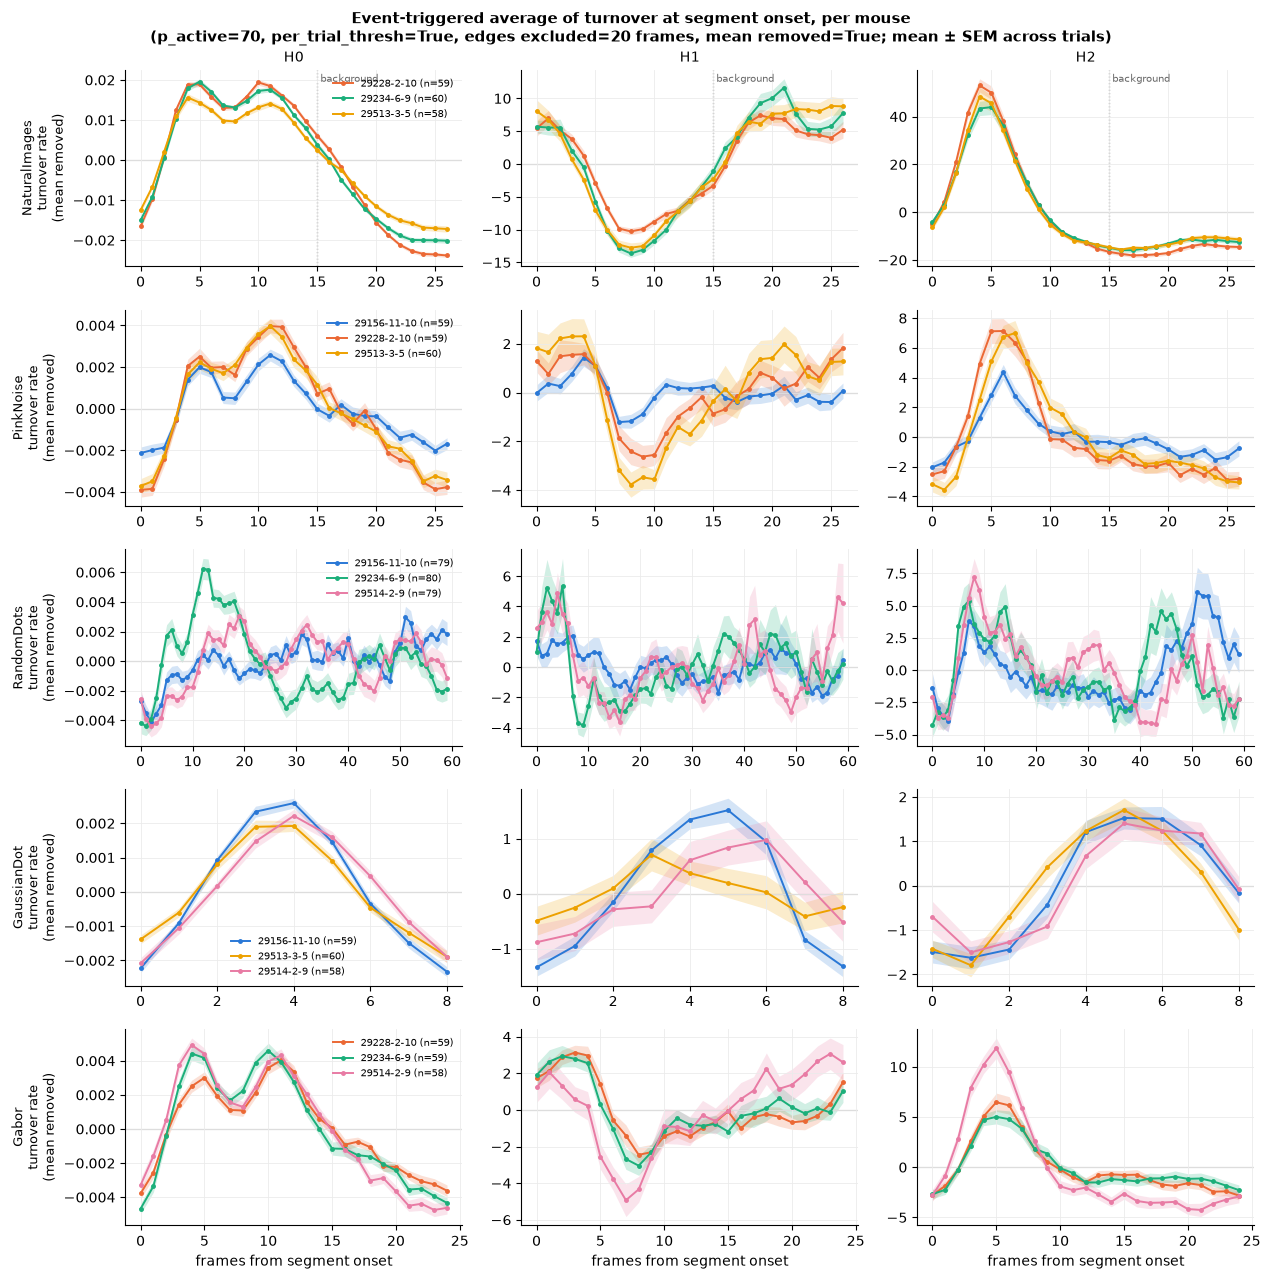

In [14]:
# One colour per mouse, fixed order across all classes (categorical slots, never cycled)
MOUSE_COLOURS_LIST = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#52514e"]
eta_mice = sorted(df_eta["mouse"].unique())
mouse_colours = {m: MOUSE_COLOURS_LIST[i] for i, m in enumerate(eta_mice)}


def plot_eta(df_eta):
    labels = [l for l in ETA_LABELS if l in set(df_eta["label"])]
    fig, axes = plt.subplots(len(labels), len(DIM_NAMES), figsize=(4.3 * len(DIM_NAMES), 2.6 * len(labels)),
                             squeeze=False)
    fig.suptitle(
        f"Event-triggered average of turnover at segment onset, per mouse\n"
        f"(p_active={P_ACTIVE}, per_trial_thresh={PER_TRIAL_THRESH}, edges excluded={ETA_EDGE_FRAMES} frames, "
        f"mean removed={ETA_REMOVE_MEAN}; mean ± SEM across trials)",
        fontsize=11, fontweight="bold",
    )
    for r, label in enumerate(labels):
        for d, dim in enumerate(DIM_NAMES):
            ax = axes[r, d]
            sub = df_eta[(df_eta["label"] == label) & (df_eta["feature"] == dim)]
            for mouse, g in sub.groupby("mouse"):
                g = g.sort_values("frame")
                c = mouse_colours[mouse]
                ax.fill_between(g["frame"], g["mean"] - g["sem"], g["mean"] + g["sem"], color=c, alpha=0.2, lw=0)
                ax.plot(g["frame"], g["mean"], color=c, lw=1.4, marker="o", ms=2.5,
                        label=f"{mouse.replace('rec-', '')} (n={g['n_trials_total'].iloc[0]})")
            if label in IMAGE_ONSET_LABELS:
                ax.axvline(15, color="0.4", lw=0.9, ls=":", zorder=0)
                ax.text(15, 0.98, " background", transform=ax.get_xaxis_transform(), fontsize=7,
                        color="0.4", va="top")
            if ETA_REMOVE_MEAN:
                ax.axhline(0, color="0.6", lw=0.8, zorder=0)
            ax.grid(color="0.92", lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            if r == 0:
                ax.set_title(dim, fontsize=10)
            if d == 0:
                ylab = "turnover rate\n(mean removed)" if ETA_REMOVE_MEAN else "turnover rate"
                ax.set_ylabel(f"{label}\n{ylab}", fontsize=9)
                ax.legend(frameon=False, fontsize=7, loc="best")
            if r == len(labels) - 1:
                ax.set_xlabel("frames from segment onset")
    fig.tight_layout()
    return fig


fig = plot_eta(df_eta)
if SAVE_FIGURES:
    FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_FOLDER / f"turnover_eta_segments_p{P_ACTIVE}_pertrial{int(PER_TRIAL_THRESH)}_demean{int(ETA_REMOVE_MEAN)}.png",
                dpi=150, bbox_inches="tight")
plt.show()